In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import  train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

In [ ]:
df = pd.read_csv("modified_data.csv")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            4600 non-null   object 
 1   price           4600 non-null   float64
 2   bedrooms        4600 non-null   float64
 3   bathrooms       4600 non-null   float64
 4   sqft_living     4600 non-null   int64  
 5   sqft_lot        4600 non-null   int64  
 6   floors          4600 non-null   float64
 7   waterfront      4600 non-null   int64  
 8   view            4600 non-null   int64  
 9   condition       4600 non-null   int64  
 10  sqft_above      4600 non-null   int64  
 11  sqft_basement   4600 non-null   int64  
 12  yr_built        4600 non-null   int64  
 13  yr_renovated    4600 non-null   int64  
 14  street          4600 non-null   object 
 15  city            4600 non-null   object 
 16  statezip        4600 non-null   object 
 17  price_per_sqft  4600 non-null   f

In [ ]:
df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
0,2014-05-02,313000.00,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,233.58
1,2014-05-02,2384000.00,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,653.15
2,2014-05-02,342000.00,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,177.20
3,2014-05-02,420000.00,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,210.00
4,2014-05-02,550000.00,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,283.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,2014-07-09,308166.67,3.0,1.75,1510,6360,1.0,0,0,4,1510,0,1954,1979,501 N 143rd St,Seattle,WA 98133,204.08
4596,2014-07-09,534333.33,3.0,2.50,1460,7573,2.0,0,0,3,1460,0,1983,2009,14855 SE 10th Pl,Bellevue,WA 98007,365.98
4597,2014-07-09,416904.17,3.0,2.50,3010,7014,2.0,0,0,3,3010,0,2009,0,759 Ilwaco Pl NE,Renton,WA 98059,138.51
4598,2014-07-10,203400.00,4.0,2.00,2090,6630,1.0,0,0,3,1070,1020,1974,0,5148 S Creston St,Seattle,WA 98178,97.32


In [ ]:
print(df[(df == 0).any(axis = 1)])

            date       price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0     2014-05-02   313000.00       3.0       1.50         1340      7912   
1     2014-05-02  2384000.00       5.0       2.50         3650      9050   
2     2014-05-02   342000.00       3.0       2.00         1930     11947   
3     2014-05-02   420000.00       3.0       2.25         2000      8030   
4     2014-05-02   550000.00       4.0       2.50         1940     10500   
...          ...         ...       ...        ...          ...       ...   
4595  2014-07-09   308166.67       3.0       1.75         1510      6360   
4596  2014-07-09   534333.33       3.0       2.50         1460      7573   
4597  2014-07-09   416904.17       3.0       2.50         3010      7014   
4598  2014-07-10   203400.00       4.0       2.00         2090      6630   
4599  2014-07-10   220600.00       3.0       2.50         1490      8102   

      floors  waterfront  view  condition  sqft_above  sqft_basement  \
0        1.5   

In [ ]:
df.columns[(df == 0).any()]

Index(['price', 'bedrooms', 'bathrooms', 'waterfront', 'view', 'sqft_basement',
       'yr_renovated', 'price_per_sqft'],
      dtype='object')

In [ ]:
(df['price_per_sqft'] == 0).sum()

np.int64(49)

In [ ]:
df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
0,2014-05-02,313000.00,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,233.58
1,2014-05-02,2384000.00,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,653.15
2,2014-05-02,342000.00,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,177.20
3,2014-05-02,420000.00,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,210.00
4,2014-05-02,550000.00,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,283.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,2014-07-09,308166.67,3.0,1.75,1510,6360,1.0,0,0,4,1510,0,1954,1979,501 N 143rd St,Seattle,WA 98133,204.08
4596,2014-07-09,534333.33,3.0,2.50,1460,7573,2.0,0,0,3,1460,0,1983,2009,14855 SE 10th Pl,Bellevue,WA 98007,365.98
4597,2014-07-09,416904.17,3.0,2.50,3010,7014,2.0,0,0,3,3010,0,2009,0,759 Ilwaco Pl NE,Renton,WA 98059,138.51
4598,2014-07-10,203400.00,4.0,2.00,2090,6630,1.0,0,0,3,1070,1020,1974,0,5148 S Creston St,Seattle,WA 98178,97.32


In [ ]:
features = [
    'price','bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
    'floors', 'condition', 'sqft_above', 'sqft_basement',
    'yr_built', 'yr_renovated',	'city',	"price_per_sqft"
    ]

In [ ]:
df_new = df[features]

In [ ]:
df_new

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,sqft_above,sqft_basement,yr_built,yr_renovated,city,price_per_sqft
0,313000.00,3.0,1.50,1340,7912,1.5,3,1340,0,1955,2005,Shoreline,233.58
1,2384000.00,5.0,2.50,3650,9050,2.0,5,3370,280,1921,0,Seattle,653.15
2,342000.00,3.0,2.00,1930,11947,1.0,4,1930,0,1966,0,Kent,177.20
3,420000.00,3.0,2.25,2000,8030,1.0,4,1000,1000,1963,0,Bellevue,210.00
4,550000.00,4.0,2.50,1940,10500,1.0,4,1140,800,1976,1992,Redmond,283.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,308166.67,3.0,1.75,1510,6360,1.0,4,1510,0,1954,1979,Seattle,204.08
4596,534333.33,3.0,2.50,1460,7573,2.0,3,1460,0,1983,2009,Bellevue,365.98
4597,416904.17,3.0,2.50,3010,7014,2.0,3,3010,0,2009,0,Renton,138.51
4598,203400.00,4.0,2.00,2090,6630,1.0,3,1070,1020,1974,0,Seattle,97.32


In [ ]:
df_new.columns[(df_new == 0).any()]

Index(['price', 'bedrooms', 'bathrooms', 'sqft_basement', 'yr_renovated',
       'price_per_sqft'],
      dtype='object')

In [ ]:
(df_new['price_per_sqft'] == 0).sum()

np.int64(49)

In [ ]:
df_new = df_new[df_new['price'] != 0]


In [ ]:
df_new

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,sqft_above,sqft_basement,yr_built,yr_renovated,city,price_per_sqft
0,313000.00,3.0,1.50,1340,7912,1.5,3,1340,0,1955,2005,Shoreline,233.58
1,2384000.00,5.0,2.50,3650,9050,2.0,5,3370,280,1921,0,Seattle,653.15
2,342000.00,3.0,2.00,1930,11947,1.0,4,1930,0,1966,0,Kent,177.20
3,420000.00,3.0,2.25,2000,8030,1.0,4,1000,1000,1963,0,Bellevue,210.00
4,550000.00,4.0,2.50,1940,10500,1.0,4,1140,800,1976,1992,Redmond,283.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,308166.67,3.0,1.75,1510,6360,1.0,4,1510,0,1954,1979,Seattle,204.08
4596,534333.33,3.0,2.50,1460,7573,2.0,3,1460,0,1983,2009,Bellevue,365.98
4597,416904.17,3.0,2.50,3010,7014,2.0,3,3010,0,2009,0,Renton,138.51
4598,203400.00,4.0,2.00,2090,6630,1.0,3,1070,1020,1974,0,Seattle,97.32


In [ ]:
import seaborn as sns

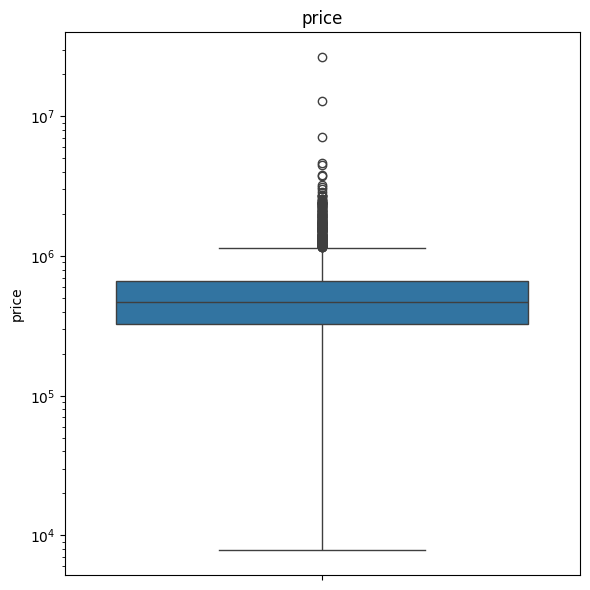

In [ ]:
plt.figure(figsize = (6, 6))
sns.boxplot(y=df_new['price'])
plt.yscale('log')
plt.title('price')
plt.tight_layout()
plt.show()

In [ ]:
# Calculate Q1, Q3 and IQR for price
Q1 = df_new['price'].quantile(0.25)
Q3 = df_new['price'].quantile(0.75)
IQR = Q3 - Q1

In [ ]:
# Define lower and upper bound
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")

Lower Bound: -170589.29
Upper Bound: 1154353.57


In [ ]:
df_new = df_new[(df_new['price'] >= lower_bound) & (df_new['price'] <= upper_bound)]

In [ ]:
df_new

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,sqft_above,sqft_basement,yr_built,yr_renovated,city,price_per_sqft
0,313000.00,3.0,1.50,1340,7912,1.5,3,1340,0,1955,2005,Shoreline,233.58
2,342000.00,3.0,2.00,1930,11947,1.0,4,1930,0,1966,0,Kent,177.20
3,420000.00,3.0,2.25,2000,8030,1.0,4,1000,1000,1963,0,Bellevue,210.00
4,550000.00,4.0,2.50,1940,10500,1.0,4,1140,800,1976,1992,Redmond,283.51
5,490000.00,2.0,1.00,880,6380,1.0,3,880,0,1938,1994,Seattle,556.82
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,308166.67,3.0,1.75,1510,6360,1.0,4,1510,0,1954,1979,Seattle,204.08
4596,534333.33,3.0,2.50,1460,7573,2.0,3,1460,0,1983,2009,Bellevue,365.98
4597,416904.17,3.0,2.50,3010,7014,2.0,3,3010,0,2009,0,Renton,138.51
4598,203400.00,4.0,2.00,2090,6630,1.0,3,1070,1020,1974,0,Seattle,97.32


In [ ]:
outlier = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]
print(outlier[['price']].sort_values('price'))

           price
418    1157200.0
3200   1157400.0
2786   1160000.0
3634   1165000.0
2670   1170000.0
...          ...
2761   4489000.0
2654   4668000.0
2286   7062500.0
4346  12899000.0
4350  26590000.0

[240 rows x 1 columns]


In [ ]:
df_new['sqft_basement'] = df_new['sqft_basement'].replace(0, pd.NA)
df_new['yr_renovated'] = df_new['yr_renovated'].replace(0, pd.NA)

/tmp/ipykernel_2525/3117040149.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_new['sqft_basement'] = df_new['sqft_basement'].replace(0, pd.NA)
/tmp/ipykernel_2525/3117040149.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_new['yr_renovated'] = df_new['yr_renovated'].replace(0, pd.NA)


In [ ]:
df_new['sqft_basement'] = df_new['sqft_basement'].fillna(df['sqft_basement'].mean())

/tmp/ipykernel_2525/1266946013.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_new['sqft_basement'] = df_new['sqft_basement'].fillna(df['sqft_basement'].mean())
/tmp/ipykernel_2525/1266946013.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_new['sqft_basement'] = df_new['sqft_basement'].fillna(df['sqft_basement'].mean())


In [ ]:
df_new['yr_renovated'] = df_new['yr_renovated'].fillna(int(df_new['yr_renovated'].mean()))

/tmp/ipykernel_2525/4145635384.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_new['yr_renovated'] = df_new['yr_renovated'].fillna(int(df_new['yr_renovated'].mean()))
/tmp/ipykernel_2525/4145635384.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_new['yr_renovated'] = df_new['yr_renovated'].fillna(int(df_new['yr_renovated'].mean()))


In [ ]:
df_new

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,sqft_above,sqft_basement,yr_built,yr_renovated,city,price_per_sqft
0,313000.00,3.0,1.50,1340,7912,1.5,3,1340,312.081522,1955,2005,Shoreline,233.58
2,342000.00,3.0,2.00,1930,11947,1.0,4,1930,312.081522,1966,1994,Kent,177.20
3,420000.00,3.0,2.25,2000,8030,1.0,4,1000,1000.000000,1963,1994,Bellevue,210.00
4,550000.00,4.0,2.50,1940,10500,1.0,4,1140,800.000000,1976,1992,Redmond,283.51
5,490000.00,2.0,1.00,880,6380,1.0,3,880,312.081522,1938,1994,Seattle,556.82
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,308166.67,3.0,1.75,1510,6360,1.0,4,1510,312.081522,1954,1979,Seattle,204.08
4596,534333.33,3.0,2.50,1460,7573,2.0,3,1460,312.081522,1983,2009,Bellevue,365.98
4597,416904.17,3.0,2.50,3010,7014,2.0,3,3010,312.081522,2009,1994,Renton,138.51
4598,203400.00,4.0,2.00,2090,6630,1.0,3,1070,1020.000000,1974,1994,Seattle,97.32


In [ ]:
print(df_new['city'].unique())
print(df_new['city'].value_counts())

['Shoreline' 'Kent' 'Bellevue' 'Redmond' 'Seattle' 'Maple Valley'
 'North Bend' 'Lake Forest Park' 'Sammamish' 'Auburn' 'Des Moines'
 'Bothell' 'Federal Way' 'Kirkland' 'Issaquah' 'Woodinville'
 'Normandy Park' 'Fall City' 'Renton' 'Carnation' 'Snoqualmie' 'Duvall'
 'Burien' 'Covington' 'Inglewood-Finn Hill' 'Kenmore' 'Newcastle'
 'Black Diamond' 'Ravensdale' 'Clyde Hill' 'Algona' 'Mercer Island'
 'Skykomish' 'Tukwila' 'Vashon' 'SeaTac' 'Enumclaw' 'Snoqualmie Pass'
 'Pacific' 'Beaux Arts Village' 'Preston' 'Milton' 'Yarrow Point' 'Medina']
city
Seattle                1461
Renton                  291
Bellevue                232
Redmond                 227
Issaquah                183
Kent                    183
Kirkland                176
Auburn                  175
Sammamish               166
Federal Way             145
Shoreline               121
Woodinville             111
Maple Valley             95
Burien                   72
Snoqualmie               69
Kenmore                  65
D

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
le = LabelEncoder()
df_new['city_encode'] = le.fit_transform(df_new['city'])


/tmp/ipykernel_2525/1395455927.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_new['city_encode'] = le.fit_transform(df_new['city'])


In [ ]:
df_clean = df_new

In [ ]:
df_clean

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,sqft_above,sqft_basement,yr_built,yr_renovated,price_per_sqft,city_encode
0,313000.00,3.0,1.50,1340,7912,1.5,3,1340,312.081522,1955,2005,233.58,36
2,342000.00,3.0,2.00,1930,11947,1.0,4,1930,312.081522,1966,1994,177.20,18
3,420000.00,3.0,2.25,2000,8030,1.0,4,1000,1000.000000,1963,1994,210.00,3
4,550000.00,4.0,2.50,1940,10500,1.0,4,1140,800.000000,1976,1992,283.51,31
5,490000.00,2.0,1.00,880,6380,1.0,3,880,312.081522,1938,1994,556.82,35
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,308166.67,3.0,1.75,1510,6360,1.0,4,1510,312.081522,1954,1979,204.08,35
4596,534333.33,3.0,2.50,1460,7573,2.0,3,1460,312.081522,1983,2009,365.98,3
4597,416904.17,3.0,2.50,3010,7014,2.0,3,3010,312.081522,2009,1994,138.51,32
4598,203400.00,4.0,2.00,2090,6630,1.0,3,1070,1020.000000,1974,1994,97.32,35


In [ ]:
df_clean.drop('city', axis = 1, inplace = True)

KeyError: "['city'] not found in axis"

In [ ]:
df_clean

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,sqft_above,sqft_basement,yr_built,yr_renovated,price_per_sqft,city_encode
0,313000.00,3.0,1.50,1340,7912,1.5,3,1340,312.081522,1955,2005,233.58,36
2,342000.00,3.0,2.00,1930,11947,1.0,4,1930,312.081522,1966,1994,177.20,18
3,420000.00,3.0,2.25,2000,8030,1.0,4,1000,1000.000000,1963,1994,210.00,3
4,550000.00,4.0,2.50,1940,10500,1.0,4,1140,800.000000,1976,1992,283.51,31
5,490000.00,2.0,1.00,880,6380,1.0,3,880,312.081522,1938,1994,556.82,35
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,308166.67,3.0,1.75,1510,6360,1.0,4,1510,312.081522,1954,1979,204.08,35
4596,534333.33,3.0,2.50,1460,7573,2.0,3,1460,312.081522,1983,2009,365.98,3
4597,416904.17,3.0,2.50,3010,7014,2.0,3,3010,312.081522,2009,1994,138.51,32
4598,203400.00,4.0,2.00,2090,6630,1.0,3,1070,1020.000000,1974,1994,97.32,35


In [ ]:
X = df_clean.drop('price', axis=1)
y = df_clean['price']

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, random_state=42, test_size=0.2
)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Model train successfully")

Model train successfully


In [ ]:
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [ ]:
r2_score = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

In [ ]:
print("-" * 30)
print(f"R2 Score: {r2_score:.2f}")
print(f"Mean absolute error: {mae:.2f}")
print(f"Mean squared error: {mse:.2f}")
print(f"Root mean squared error: {rmse:.2f}")

------------------------------
R2 Score: 0.88
Mean absolute error: 47221.38
Mean squared error: 5439845469.95
Root mean squared error: 73755.31


In [ ]:
df_clean.drop('predicted price', axis = 1, inplace=True)

/tmp/ipykernel_2525/871702652.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean.drop('predicted price', axis = 1, inplace=True)


In [ ]:
X_scaled_full = scaler.fit_transform(X)
df_clean['predicted_price'] = model.predict(X_scaled_full)

/tmp/ipykernel_2525/619055029.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['predicted_price'] = model.predict(X_scaled_full)


In [ ]:
df_clean[['price', 'predicted_price']]

,price,predicted_price
0,313000.00,290293.018685
2,342000.00,342058.364996
3,420000.00,408792.540504
4,550000.00,529330.819163
5,490000.00,697432.402633
...,...,...
4595,308166.67,285953.316137
4596,534333.33,544512.974796
4597,416904.17,517477.460034
4598,203400.00,240429.400886


In [ ]:
df_clean.columns

Index(['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated',
       'price_per_sqft', 'city_encode', 'predicted_price'],
      dtype='object')

In [ ]:
bedrooms = int(input("Enter the no of bedrooms: "))
bathrooms = int(input("Enter the no of bathrooms: "))
sqft_living = float(input("Enter the square fit living: "))
sqft_lot = float(input("Enter the square fit lot: "))
floors = int(input("Enter the no of floors: "))
condition = int(input("Enter the number of condition: "))
sqft_above = float(input("Enter the square fit above: "))
sqft_basement = float(input("Enter the square fit basement: "))
yr_built = int(input("Enter the year in which it is built: "))
yr_renovated = int(input("Enter the year in which it is renovated: "))
price_per_sqft = float(input("Enter the price per square fit: "))
city = input("enter the city name: ").strip().title()

# Encoded city
encoded_city = le.transform([city])[0]

# New house
new_house = pd.DataFrame({
    'bedrooms': [bedrooms],
    'bathrooms': [bathrooms],
    'sqft_living': [sqft_living],
    'sqft_lot': [sqft_lot],
    'floors': [floors],
    'condition': [condition],
    'sqft_above': [sqft_above],
    'sqft_basement': [sqft_basement],
    'yr_built': [yr_built],
    'yr_renovated': [yr_renovated],
    'price_per_sqft': [price_per_sqft],
    'city_encode': [encoded_city]
})

new_house_scaled = scaler.transform(new_house)
print("New house price: ", round(model.predict(new_house_scaled)[0], 2))

Enter the no of bedrooms: 3
Enter the no of bathrooms: 3
Enter the square fit living: 1340
Enter the square fit lot: 7912
Enter the no of floors: 1
Enter the number of condition: 3
Enter the square fit above: 1340
Enter the square fit basement: 0
Enter the year in which it is built: 1995
Enter the year in which it is renovated: 2005
Enter the price per square fit: 233.58
enter the city name: kent
New house price:  338299.65


In [ ]:
df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
0,2014-05-02,313000.00,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,233.58
1,2014-05-02,2384000.00,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,653.15
2,2014-05-02,342000.00,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,177.20
3,2014-05-02,420000.00,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,210.00
4,2014-05-02,550000.00,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,283.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,2014-07-09,308166.67,3.0,1.75,1510,6360,1.0,0,0,4,1510,0,1954,1979,501 N 143rd St,Seattle,WA 98133,204.08
4596,2014-07-09,534333.33,3.0,2.50,1460,7573,2.0,0,0,3,1460,0,1983,2009,14855 SE 10th Pl,Bellevue,WA 98007,365.98
4597,2014-07-09,416904.17,3.0,2.50,3010,7014,2.0,0,0,3,3010,0,2009,0,759 Ilwaco Pl NE,Renton,WA 98059,138.51
4598,2014-07-10,203400.00,4.0,2.00,2090,6630,1.0,0,0,3,1070,1020,1974,0,5148 S Creston St,Seattle,WA 98178,97.32
